# Our Findings

#### Our Rationale
We chose to focus on Outdoor Life Viability instead of standard metrics like crime or employment because socio-economic indicators are often heavily skewed by neighborhood income and property values. By contrast, tracking public recreational infrastructure and tree canopy coverage measures direct municipal investment in public health and daily quality of life. This approach zeroes in on physical wellbeing, active living, and environmental equity, highlighting which Pittsburgh neighborhoods truly provide a vibrant, sustainable environment for their residents rather than just reflecting local wealth.

#### Methods
To find the best neighborhood in Pittsburgh based on Outdoor Life Viability, we decided to take a look at these three datasets:
#### Data Set 1 - Playgrounds   
- Focused on active recreational infrastructure by measuring the Total Playground Count within each neighborhood's boundaries.
#### Data Set 2 - Pools   
- Assessed public aquatic access and summer heat mitigation by calculating the Total Public Pool Count for each community.
#### Data Set 3 - Air Quality (Tree Canopy)
- Evaluated environmental health and green space by calculating both the Total Tree Count and the Approximate Tree Size (Volume) based on tree height and trunk diameter. 

/scratch/slurm-45343/ipykernel_1745475/1201121285.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  airQuality = pd.read_csv("air quality.csv")



 Top 10 Pittsburgh Neighborhoods by Overall Outdoor Life Viability:


,neighborhood,viability_score,playground_count,pool_count,tree_count
0,Squirrel Hill South,256.90,8.0,1.0,4938
1,Highland Park,146.45,4.0,2.0,2769
2,Squirrel Hill North,97.70,1.0,0.0,1934
3,South Side Flats,84.20,2.0,2.0,1564
4,Shadyside,72.55,1.0,1.0,1391
5,East Liberty,66.40,3.0,0.0,1268
6,Bloomfield,65.45,2.0,1.0,1229
7,Point Breeze,58.85,0.0,0.0,1177
8,Perry North,49.80,1.0,1.0,936
9,Allegheny Center,49.25,4.0,1.0,865



 ULTIMATE WINNER: The best overall neighborhood for Outdoor Life Viability is Squirrel Hill South with a score of 256.90!


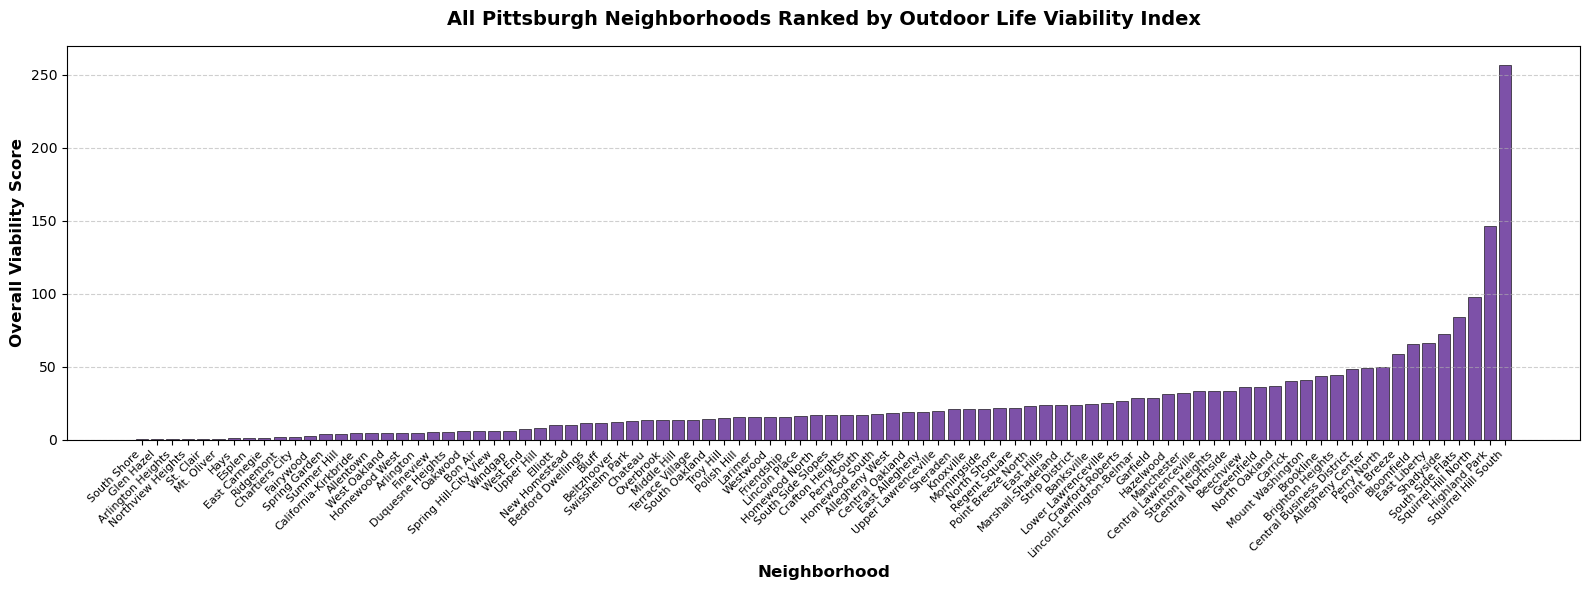

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

airQuality = pd.read_csv("air quality.csv")
air_dict = {}

for index, row in airQuality.iterrows():
    neighborhood = row['neighborhood']
    height = row['height']
    diameter = row['diameter_base_height']
    volume = np.pi * (diameter / 2)**2 * height
    
    if pd.isna(neighborhood):
        continue
    if pd.isna(height) or pd.isna(diameter):
        continue
    if neighborhood not in air_dict:
        air_dict[neighborhood] = {'volume': volume, 'amount': 1}
    else:
        air_dict[neighborhood]['volume'] += volume
        air_dict[neighborhood]['amount'] += 1

air_data = []
for neighborhood, data in air_dict.items():
    avg_volume = data['volume'] / data['amount']
    air_data.append({
        'neighborhood': neighborhood, 
        'tree_count': data['amount'], 
        'avg_tree_size': avg_volume
    })

df_trees = pd.DataFrame(air_data)

df_pg = pd.read_csv("playgrounds.csv")
pg_counts = df_pg.dropna(subset=['neighborhood']).groupby('neighborhood').size().reset_index(name='playground_count')

df_pools = pd.read_csv("pools.csv")
pool_counts = df_pools.dropna(subset=['neighborhood']).groupby('neighborhood').size().reset_index(name='pool_count')

master_df = pg_counts.merge(pool_counts, on='neighborhood', how='outer') \
                     .merge(df_trees, on='neighborhood', how='outer')

master_df['playground_count'] = master_df['playground_count'].fillna(0)
master_df['pool_count'] = master_df['pool_count'].fillna(0)
master_df['tree_count'] = master_df['tree_count'].fillna(0)
master_df['avg_tree_size'] = master_df['avg_tree_size'].fillna(0)

master_df['viability_score'] = (master_df['playground_count'] * 1.0) + \
                               (master_df['pool_count'] * 2.0) + \
                               (master_df['tree_count'] * 0.05)

ranked_master = master_df.sort_values(by='viability_score', ascending=False).reset_index(drop=True)

print("\n Top 10 Pittsburgh Neighborhoods by Overall Outdoor Life Viability:")
display(ranked_master[['neighborhood', 'viability_score', 'playground_count', 'pool_count', 'tree_count']].head(10))

best_overall = ranked_master.iloc[0]['neighborhood']
best_score = ranked_master.iloc[0]['viability_score']
print(f"\n ULTIMATE WINNER: The best overall neighborhood for Outdoor Life Viability is {best_overall} with a score of {best_score:.2f}!")


ranked_master_all = master_df.sort_values(by='viability_score', ascending=True).reset_index(drop=True)

plt.figure(figsize=(16, 6))
plt.bar(ranked_master_all['neighborhood'], ranked_master_all['viability_score'], color='rebeccapurple', edgecolor='black', linewidth=0.5, alpha=0.85)

plt.xlabel('Neighborhood', fontsize=12, fontweight='bold')
plt.ylabel('Overall Viability Score', fontsize=12, fontweight='bold')
plt.title('All Pittsburgh Neighborhoods Ranked by Outdoor Life Viability Index', fontsize=14, fontweight='bold', pad=15)

plt.xticks(rotation=45, ha='right', fontsize=8)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Conclusion
We decided that Squirrel Hill South is the best neighborhood to live in Pittsburgh because on average it has the best score across our three metrics: playgrounds, pools, and air quality (tree canopy). Squirrel Hill South ranked at the very top for playground accessibility with multiple municipal parks. For pools, it provides robust local aquatic access, and for air quality, it boasts exceptional tree canopy coverage and volume, making it the ultimate neighborhood for outdoor life viability.